# 04 · HNSW from scratch: the graph most vector databases use

**The question.** IVF skips comparisons by clustering; PQ shrinks vectors. Can we skip *almost
all* comparisons and still find the right neighbourhood?

**The claim.** Link every vector to a handful of near neighbours, add a few sparse "express"
layers on top, and search becomes a walk: start anywhere, step to whichever neighbour is closer
to the query, repeat. The walk reaches the query's neighbourhood in roughly logarithmic hops, so
the share of the database it scores *shrinks* as the database grows. This is HNSW — the
hierarchical navigable small-world graph of Malkov & Yashunin (2018) — and it is what pgvector,
Weaviate, Qdrant, Milvus and most other vector databases run by default.

**By the end** you will have built HNSW from scratch in about 300 lines of Python
(`src/indexes/hnsw.py`), watched one query walk down its layers, measured the sub-linear work,
and learned what its two knobs — graph degree `m` and search breadth `ef_search` — buy and cost.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import visualisation as vis
from src.artifacts import save_figure, save_json
from src.config import get_settings
from src.datasets.vectors import load_dataset
from src.evaluation.speed import machine_info, pinned_threads

S = get_settings()
K, SEED, THREADS = S.eval.k, S.seed, S.bench.threads
NB_START = time.perf_counter()
MACHINE = machine_info(THREADS)
pd.set_option("display.width", 140, "display.max_colwidth", 90)


def show(fig, slug: str) -> None:
    """Save the figure as outputs/figures/<slug>.png, then display it once."""
    save_figure(fig, slug)
    plt.close(fig)
    display(fig)


print(MACHINE)

{'cpu': 'Intel(R) Xeon(R) Platinum 8370C CPU @ 2.80GHz', 'logical_cpus': 2, 'threads': 1, 'python': '3.14.2', 'numpy': '2.5.4', 'faiss': '1.15.1', 'hnswlib': '0.8.0'}


## How it is built

Every vector is a node. When a node is inserted it draws a top level
$\ell = \lfloor -\ln(U)\cdot m_L \rfloor$ with $m_L = 1/\ln m$: everyone lives on layer 0, about one
node in `m` also on layer 1, one in `m²` on layer 2, and so on.

- **Insert** (paper Alg. 1): walk greedily down from the entry point to the new node's level;
  then on each layer from there to 0, run a beam search `ef_construction` wide, pick `m`
  neighbours with the *diversity heuristic*, and link both ways. A list may grow to `2m` links on
  layer 0 and `m` above; when it overflows, it is re-pruned with the same heuristic.
- **Search** (Alg. 5): one greedy step per upper layer (zoom in), then a beam search of width
  `max(ef_search, k)` on layer 0.

The heuristic is what makes the graph navigable. Taking the `m` closest candidates would link a
node only to its own tight cluster; instead, a candidate is skipped if an already-chosen neighbour
is closer to it than the new node is — so links point in *different directions*, including the
long ones that bridge clusters:

In [2]:
import inspect

from src.indexes.hnsw import HNSWIndex

print(inspect.getsource(HNSWIndex._select_neighbors))

    def _select_neighbors(self, cand: np.ndarray, cand_d: np.ndarray, cap: int) -> np.ndarray:
        """Diversity heuristic (Alg. 4, as hnswlib's ``getNeighborsByHeuristic2``).

        Scan candidates nearest-first; keep ``c`` unless an already-kept ``r`` is closer to it
        than the base is (``d(c, r) < d(c, base)``). That skips near-duplicates of links we
        already have and keeps links pointing in different directions — what makes the graph
        navigable across clusters.
        """
        order = np.argsort(cand_d, kind="stable")
        cand, cand_d = cand[order], cand_d[order]
        if cand.size < cap:
            return cand
        vecs = self._xb[cand]
        norms = self._norms[cand]
        pair = norms[:, None] + norms[None, :] - 2.0 * (vecs @ vecs.T)
        kept: list[int] = []
        for a in range(cand.size):
            if kept and bool((pair[a, kept] < cand_d[a]).any()):
                continue
            kept.append(a)
            if len(kept) 

## Build it, and measure as it grows

The from-scratch build is pure Python with numpy for the distances, so it is capped at 20,000
news vectors (about a minute on one core; hnswlib and faiss supply the larger numbers below).
HNSW is built by insertion, so the graph after the first `n` inserts *is* the graph on those `n`
vectors. Pausing at each size and searching 300 held-out queries gives the whole size ladder from
one build.

In [3]:
from src.artifacts import indexes_dir
from src.datasets.vectors import exact_ground_truth
from src.evaluation.recall import recall_at_k
from src.indexes.hnsw import cache_path

news = load_dataset("news")
h = S.hnsw
n_scratch = h.max_scratch_n
xb = news.base[:n_scratch]
xq = news.queries[: S.bench.max_queries]
ladder_sizes = [*h.ladder, n_scratch]

graph = HNSWIndex(m=h.m, ef_construction=h.ef_construction, ef_search=h.ef_search, seed=SEED)
ladder, start, build_s = [], 0, 0.0
for n in ladder_sizes:
    t0 = time.perf_counter()
    graph.add(xb[start:n])
    build_s += time.perf_counter() - t0
    start = n
    gt_n, _ = exact_ground_truth(xb[:n], xq, K)
    _, ids = graph.search(xq, K)
    ladder.append({"n": n, "recall": recall_at_k(ids, gt_n, K), "work": float(graph.last_stats.ndis.mean()),
                   "hops": float(graph.last_stats.nhops.mean()), "build_s_cumulative": build_s})
graph.save(cache_path(news.key, n_scratch, h.m, h.ef_construction, SEED))  # reused by notebook 05 and the app
scratch_ladder = pd.DataFrame(ladder)
scratch_ladder["share_scored"] = scratch_ladder["work"] / scratch_ladder["n"]
print(f"built {graph.ntotal:,} nodes in {build_s:.0f} s ({1e3 * build_s / graph.ntotal:.2f} ms per insert), "
      f"{graph.max_level + 1} layers, reachable from the entry point: {graph.reachable_fraction():.2%}")
display(scratch_ladder.round(3))

built 20,000 nodes in 51 s (2.53 ms per insert), 4 layers, reachable from the entry point: 100.00%


,n,recall,work,hops,build_s_cumulative,share_scored
0,1000,0.999,594.083,66.343,2.049,0.594
1,2000,0.998,735.480,66.480,4.342,0.368
2,4000,0.993,848.657,66.657,9.150,0.212
3,8000,0.989,912.300,67.837,19.271,0.114
4,16000,0.983,974.237,68.343,40.113,0.061
5,20000,0.978,988.993,68.377,50.699,0.049


## The layers, and one query's walk

Left: how many nodes live on each layer, against the geometric law the level draw implies.
Right: every distance computed by one query, in order. On the upper layers the walk takes a few
greedy hops, each strictly closer to the query; on layer 0 the beam search expands candidates
around the neighbourhood it has reached.

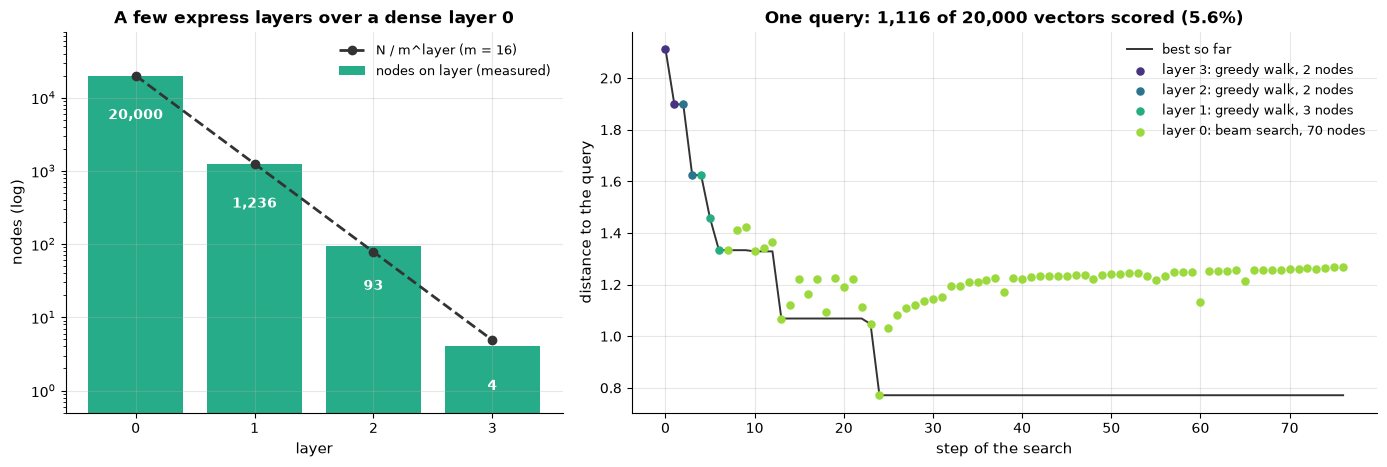

query: "The Divine Invasion" God invades Earth by making a young woman pregnant as she returns from another star system.
  -> So Mary comes up with this ridiculous story about God making her pregnant.
  -> At least it has a fairly popular orginating premise; everyone I'd mention the idea to thought it was either divinely inspired or at least past due for delivery.
  -> The Bible in one place refers to God as being like a mother.
  -> And now divine nature is now within lives our very being--and us and God communicate with each through his unifying Holy Spirit.
  -> Also, she has been preparing the new Eden, by reversing the deed of the ancient Eve.


In [4]:
qi = next(i for i, t in enumerate(news.query_texts) if len(t.split()) >= 12)
trace = graph.trace(news.queries[qi], K)
fig = vis.plot_hnsw_layers_walk(graph.level_counts(), h.m, trace.hops, trace.ndis, graph.ntotal)
show(fig, "04_hnsw_layers_and_walk")
gt_q, _ = exact_ground_truth(xb, news.queries[qi : qi + 1], K)
walk = {
    "query": news.query_texts[qi], "n": graph.ntotal, "m": h.m, "ef_search": h.ef_search,
    "level_counts": graph.level_counts(), "vectors_scored": trace.ndis,
    "greedy_hops_per_upper_layer": {lay: len(p) - 1 for lay, p in trace.layer_paths.items() if lay > 0},
    "layer0_expansions": len(trace.layer_paths[0]),
    "recall_this_query": len(set(trace.ids) & set(gt_q[0].tolist())) / K,
    "neighbours": [news.texts[i] for i in trace.ids[:5]],
}
save_json("04_hnsw_layers_and_walk", walk)
print("query:", walk["query"])
for s in walk["neighbours"]:
    print("  ->", s)

## Sub-linear work

Exact search scores all `N` vectors. HNSW scores a number that grows far more slowly — so the
*share* of the database it touches falls as the database grows. Three ladders, all at
`m = 16`, `ef_search = 64`: the from-scratch build above (news, to 20k), faiss's `IndexHNSWFlat`
on the same news vectors (to 50k), and faiss on the 200,000-vector clustered set. faiss reports
its distance count through `hnsw_stats`, so work is measured the same way in all three.

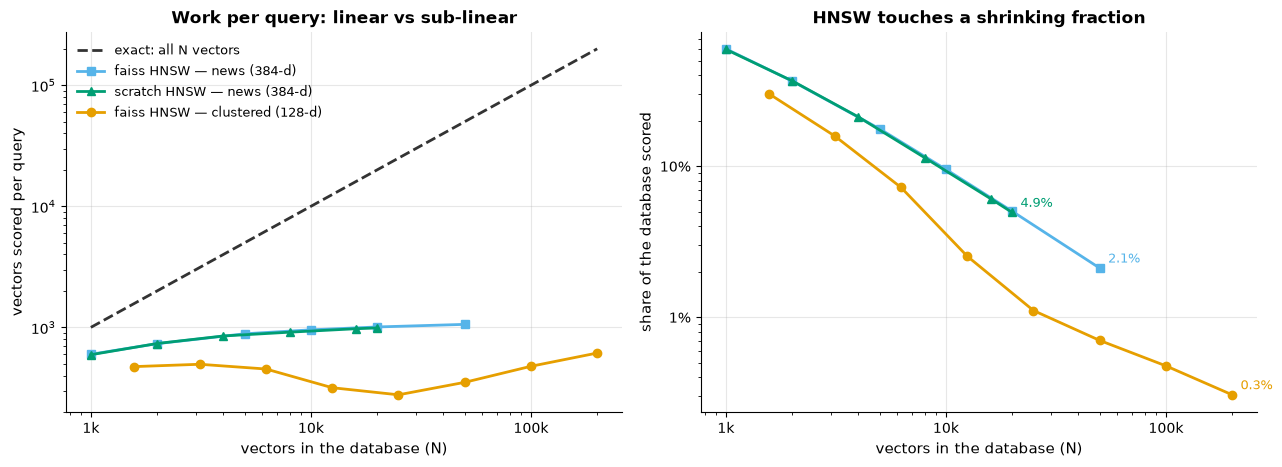

n  recall      work
scratch news    0    1000   0.999   594.083
                1    2000   0.998   735.480
                2    4000   0.993   848.657
                3    8000   0.989   912.300
                4   16000   0.983   974.237
                5   20000   0.978   988.993
faiss news      0    1000   0.999   599.030
                1    2000   0.998   733.520
                2    5000   0.993   884.647
                3   10000   0.989   953.693
                4   20000   0.979  1007.677
                5   50000   0.972  1058.443
faiss clustered 0    1563   1.000   473.747
                1    3125   1.000   495.520
                2    6250   1.000   452.823
                3   12500   1.000   317.293
                4   25000   1.000   277.180
                5   50000   1.000   351.413
                6  100000   1.000   476.893
                7  200000   0.989   613.577

clustered: N grows 128x while work per query stays between 277 and 614 vectors
news (scratch): N grows 20x, work grows 1.7x


In [5]:
from src.reference.compare import FaissHNSW

def faiss_ladder(ds, sizes):
    ref = FaissHNSW(m=h.m, ef_construction=h.ef_construction, ef_search=h.ef_search)
    out, start = [], 0
    q = ds.queries[: S.bench.max_queries]
    for n in sizes:
        ref.add(ds.base[start:n])
        start = n
        gt_n, _ = exact_ground_truth(ds.base[:n], q, K)
        _, ids = ref.search(q, K)
        out.append({"n": n, "recall": recall_at_k(ids, gt_n, K), "work": float(ref.last_stats.ndis.mean())})
    return pd.DataFrame(out)

clustered = load_dataset("clustered")
with pinned_threads(THREADS):
    faiss_news = faiss_ladder(news, [1000, 2000, 5000, 10000, 20000, 50000])
    faiss_clustered = faiss_ladder(clustered, [1563, 3125, 6250, 12500, 25000, 50000, 100000, 200000])
ladders = [  # faiss first, so the scratch triangles are drawn on top of the matching squares
    {"label": "faiss HNSW — news (384-d)", "n": faiss_news["n"], "work": faiss_news["work"],
     "color": "#56B4E9", "marker": "s"},
    {"label": "scratch HNSW — news (384-d)", "n": scratch_ladder["n"], "work": scratch_ladder["work"],
     "color": vis.INDEX_COLORS["hnsw"], "marker": "^"},
    {"label": "faiss HNSW — clustered (128-d)", "n": faiss_clustered["n"], "work": faiss_clustered["work"],
     "color": "#E69F00", "marker": "o"},
]
fig = vis.plot_hnsw_sublinear(ladders)
show(fig, "04_hnsw_sublinear")
save_json("04_hnsw_sublinear", {"m": h.m, "ef_search": h.ef_search, "k": K, "scratch_news": scratch_ladder,
                                "faiss_news": faiss_news, "faiss_clustered": faiss_clustered})
display(pd.concat({"scratch news": scratch_ladder[["n", "recall", "work"]], "faiss news": faiss_news,
                   "faiss clustered": faiss_clustered}).round(3))
growth = faiss_clustered["n"].iloc[-1] / faiss_clustered["n"].iloc[0]
print(f"clustered: N grows {growth:.0f}x while work per query stays between "
      f"{faiss_clustered['work'].min():.0f} and {faiss_clustered['work'].max():.0f} vectors")
print(f"news (scratch): N grows {scratch_ladder['n'].iloc[-1] / scratch_ladder['n'].iloc[0]:.0f}x, "
      f"work grows {scratch_ladder['work'].iloc[-1] / scratch_ladder['work'].iloc[0]:.1f}x")

Going from 1,000 to 20,000 news vectors multiplies `N` by 20 but the work by less than 2, and on the
clustered set `N` grows more than a hundredfold while the work stays in the same few hundred
vectors (printed above). The from-scratch graph and faiss's do nearly the same amount of work on the
same data — the Python version is slower in wall-clock time, not in the algorithm.

## The knobs: `ef_search` and `m`

`ef_search` is a search-time knob: a wider beam explores more of the graph before it stops, so
recall goes up and so does the work. `m` is a build-time knob: more links per node make the graph
easier to navigate, but every link costs 4 bytes per node (8 on layer 0, where lists hold `2m`)
and every insert has to maintain them. Sweep both on the first 10,000 news vectors, with
hnswlib (the C++ library most vector databases embed) at `m = 16` for reference.

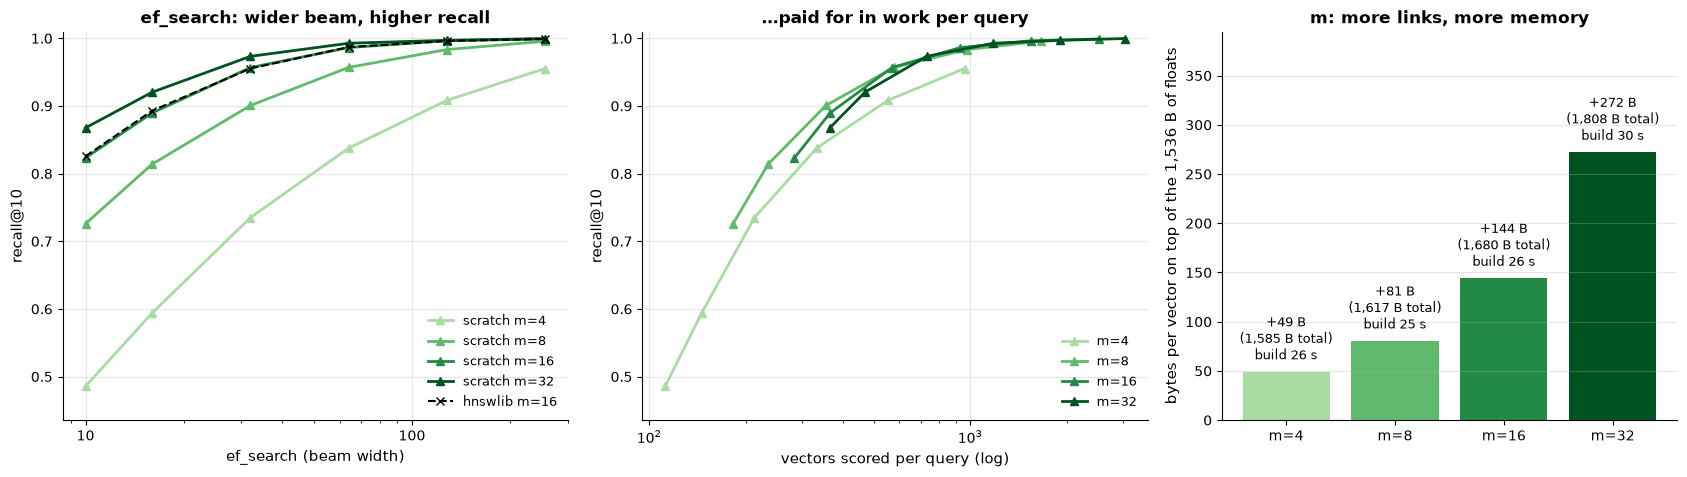

m,4,8,16,32
ef_search,,,,
10,0.486,0.726,0.823,0.868
16,0.594,0.814,0.890,0.920
32,0.735,0.901,0.957,0.973
64,0.838,0.957,0.986,0.993
128,0.908,0.983,0.996,0.997
256,0.955,0.996,0.999,1.000


,m,build_s,bytes_per_vector,reachable
0,4,26.485,1585.261,0.995
1,8,24.895,1616.557,1.000
2,16,25.844,1680.243,1.000
3,32,30.310,1808.262,1.000


In [6]:
from src.evaluation.memory import exact_bytes
from src.evaluation.triangle import expand_params, sweep, to_frame
from src.reference.compare import HnswlibHNSW

n_sw = h.sweep_n
xs, (gt_sw, _) = news.base[:n_sw], exact_ground_truth(news.base[:n_sw], xq, K)
rows, builds = [], []
for m in h.m_sweep:
    idx = HNSWIndex(m=m, ef_construction=h.ef_construction, seed=SEED)
    t0 = time.perf_counter()
    idx.add(xs)
    secs = time.perf_counter() - t0
    builds.append({"m": m, "build_s": secs, "bytes_per_vector": idx.nbytes / n_sw, "reachable": idx.reachable_fraction()})
    rows += sweep(idx, "ef_search", h.ef_search_sweep, xq, gt_sw, K, engine="scratch", dataset="news",
                  build_params={"m": m, "ef_construction": h.ef_construction}, build_s=secs, seed=SEED, threads=THREADS)
knobs = expand_params(to_frame(rows))
with pinned_threads(THREADS):
    ref = HnswlibHNSW(m=h.m, ef_construction=h.ef_construction, seed=SEED, threads=THREADS)
    ref.add(xs)
    hl_rows = sweep(ref, "ef_search", h.ef_search_sweep, xq, gt_sw, K, engine="hnswlib", dataset="news",
                    build_params={"m": h.m, "ef_construction": h.ef_construction}, build_s=float("nan"),
                    seed=SEED, threads=THREADS)
hnswlib_curve = expand_params(to_frame(hl_rows))
builds = pd.DataFrame(builds)
fig = vis.plot_hnsw_knobs(knobs, hnswlib_curve, builds, exact_bytes(n_sw, news.d) / n_sw, K)
show(fig, "04_hnsw_knobs")
save_json("04_hnsw_knobs", {"n": n_sw, "k": K, "ef_construction": h.ef_construction,
                            "scratch": knobs[["m", "ef_search", "recall", "work", "work_speedup", "bytes_per_vector"]],
                            "hnswlib": hnswlib_curve[["m", "ef_search", "recall"]], "builds": builds})
display(knobs.pivot(index="ef_search", columns="m", values="recall").round(3))
display(builds.round(3))

## Checked against hnswlib

Same vectors (the 20,000-node graph built above), same `m` and `ef_construction`, same queries:

In [7]:
check = []
with pinned_threads(THREADS):
    ref = HnswlibHNSW(m=h.m, ef_construction=h.ef_construction, seed=SEED, threads=THREADS)
    t0 = time.perf_counter()
    ref.add(xb)
    hnswlib_build_s = time.perf_counter() - t0
    gt20, _ = exact_ground_truth(xb, xq, K)
    for ef in (16, 64, 256):
        graph.ef_search = ref.ef_search = ef
        _, ids_s = graph.search(xq, K)
        _, ids_r = ref.search(xq, K)
        check.append({"ef_search": ef, "scratch_recall": recall_at_k(ids_s, gt20, K),
                      "hnswlib_recall": recall_at_k(ids_r, gt20, K), "scratch_work": float(graph.last_stats.ndis.mean())})
check = pd.DataFrame(check)
check["recall_gap"] = (check["scratch_recall"] - check["hnswlib_recall"]).abs()
save_json("04_vs_hnswlib", {"n": n_scratch, "m": h.m, "ef_construction": h.ef_construction, "rows": check,
                            "scratch_bytes": graph.nbytes, "hnswlib_bytes": ref.nbytes,
                            "scratch_build_s": build_s, "hnswlib_build_s": hnswlib_build_s})
display(check.round(3))
print(f"analytic size: scratch {vis.human_bytes(graph.nbytes)} vs hnswlib file {vis.human_bytes(ref.nbytes)}")

,ef_search,scratch_recall,hnswlib_recall,scratch_work,recall_gap
0,16,0.866,0.862,391.087,0.004
1,64,0.978,0.977,988.993,0.000
2,256,0.997,0.998,2799.103,0.001


analytic size: scratch 33.6 MB vs hnswlib file 33.7 MB


In [8]:
last = scratch_ladder.iloc[-1]
top = knobs[knobs["m"] == h.m].set_index("ef_search")
fc = faiss_clustered.iloc[-1]
summary = {
    "scratch_n": int(last["n"]), "scratch_build_s": build_s, "scratch_work_at_20k": float(last["work"]),
    "scratch_share_at_20k": float(last["share_scored"]), "scratch_recall_at_20k": float(last["recall"]),
    "faiss_clustered_share_at_200k": float(fc["work"] / fc["n"]), "faiss_clustered_recall_at_200k": float(fc["recall"]),
    "recall_ef10_m16": float(top.loc[min(h.ef_search_sweep), "recall"]),
    "recall_ef256_m16": float(top.loc[max(h.ef_search_sweep), "recall"]),
    "bytes_per_vector_m16": float(builds.loc[builds["m"] == h.m, "bytes_per_vector"].iloc[0]),
    "exact_bytes_per_vector": news.d * 4,
    "max_recall_gap_vs_hnswlib": float(check["recall_gap"].max()), "hnswlib_build_s": hnswlib_build_s,
    "runtime_s": time.perf_counter() - NB_START,
}
save_json("04_summary", summary)
display(Markdown(f'''
### What this bought you, and what it cost

- **Bought:** speed that scales. At {summary["scratch_n"]:,} news vectors the graph scores
  {summary["scratch_work_at_20k"]:.0f} vectors per query ({summary["scratch_share_at_20k"]:.1%} of the
  database) for recall@10 of {summary["scratch_recall_at_20k"]:.2f}; faiss's HNSW on 200,000 clustered
  vectors scores {summary["faiss_clustered_share_at_200k"]:.2%} of them at recall
  {summary["faiss_clustered_recall_at_200k"]:.2f}. `ef_search` slides recall from
  {summary["recall_ef10_m16"]:.2f} to {summary["recall_ef256_m16"]:.2f} with no rebuild.
- **Cost:** memory and build time. HNSW keeps every float *and* the links:
  {summary["bytes_per_vector_m16"]:.0f} bytes per vector at `m = {h.m}` against
  {summary["exact_bytes_per_vector"]} for the floats alone — more than exact search, the opposite
  corner from PQ. Building the 20,000-node graph took {summary["scratch_build_s"]:.0f} s in Python
  ({summary["hnswlib_build_s"]:.1f} s in hnswlib's C++), and every insert must maintain the links.
- **Trust:** recall matches hnswlib within {summary["max_recall_gap_vs_hnswlib"]:.3f} at every
  `ef_search` checked.
'''))
print(f"notebook runtime: {summary['runtime_s']:.0f} s")


### What this bought you, and what it cost

- **Bought:** speed that scales. At 20,000 news vectors the graph scores
  989 vectors per query (4.9% of the
  database) for recall@10 of 0.98; faiss's HNSW on 200,000 clustered
  vectors scores 0.31% of them at recall
  0.99. `ef_search` slides recall from
  0.82 to 1.00 with no rebuild.
- **Cost:** memory and build time. HNSW keeps every float *and* the links:
  1680 bytes per vector at `m = 16` against
  1536 for the floats alone — more than exact search, the opposite
  corner from PQ. Building the 20,000-node graph took 51 s in Python
  (3.0 s in hnswlib's C++), and every insert must maintain the links.
- **Trust:** recall matches hnswlib within 0.004 at every
  `ef_search` checked.


notebook runtime: 218 s
